# Mental Health and Seasonality: Daylight, Temperature and Well-being Across Cities

**Course project: data collection and preparation pipeline**

## 1. Project overview

**Research question.** How do seasonal factors (daylight duration, temperature, sunshine) relate to a population-level mental health indicator across cities and countries?

**Data sources**

* **Open-Meteo Historical Weather API** (API, JSON): daily mean temperature, daylight duration and sunshine duration for 28 cities, 2019 to 2023.
* **Wikipedia: List of countries by suicide rate** (web scraping with requests + BeautifulSoup): country level mental health indicator, suicide rate per 100,000 people.
* **Wikipedia: List of cities by sunshine duration** (web scraping with requests + BeautifulSoup): annual sunshine hours per city, used to cross-check the API.

**Why suicide rate?** Wikipedia has no clean static table of seasonal affective disorder (SAD) prevalence by country. The suicide rate is the most widely tabulated, comparable mental health outcome on a static page, so it is used here as a **proxy** for population mental health. It is not a measure of SAD, and this limitation is discussed in the conclusion.

**Hypotheses**

1. Cities with stronger seasonal swings in daylight (higher latitude) show different suicide rates than cities with stable daylight.
2. Within a city, temperature and daylight move together through the year (a sanity check of the weather data).
3. The sunshine hours reported by the API rank cities in the same order as the hours reported on Wikipedia, and we check whether the absolute values also agree.

**Pipeline:** collect (API + scraping) then clean then merge then explore (EDA) then visualize then conclude.

## 2. Setup

In [1]:
import re
import time
import unicodedata
from pathlib import Path
from urllib import robotparser

import numpy as np
import pandas as pd
import requests
from bs4 import BeautifulSoup

import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as st

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)

DATA_DIR = Path("data")
FIG_DIR = Path("figures")
DATA_DIR.mkdir(exist_ok=True)
FIG_DIR.mkdir(exist_ok=True)

# Wikipedia asks scrapers to identify themselves
HEADERS = {"User-Agent": "Mozilla/5.0 (university data course project; seasonality and mental health)"}

## 3. Data source 1: Open-Meteo API

We pick 28 cities that cover a wide range of latitudes in both hemispheres, so that the seasonal contrast in daylight is large. For each city we request **daily** values for five full years (2019 to 2023):

* `temperature_2m_mean`: mean daily air temperature in degrees Celsius
* `daylight_duration`: seconds between sunrise and sunset
* `sunshine_duration`: seconds of actual direct sunshine (daylight minus cloud cover effects)

The raw API responses are cached in `data/raw_weather.csv`, so the notebook only calls the API once.

In [2]:
CITIES = [
    ("Reykjavik", "Iceland", 64.15, -21.94),
    ("Oslo", "Norway", 59.91, 10.75),
    ("Helsinki", "Finland", 60.17, 24.94),
    ("Stockholm", "Sweden", 59.33, 18.07),
    ("Dublin", "Ireland", 53.35, -6.26),
    ("London", "United Kingdom", 51.51, -0.13),
    ("Berlin", "Germany", 52.52, 13.40),
    ("Paris", "France", 48.86, 2.35),
    ("Vienna", "Austria", 48.21, 16.37),
    ("Almaty", "Kazakhstan", 43.24, 76.89),
    ("Madrid", "Spain", 40.42, -3.70),
    ("Rome", "Italy", 41.90, 12.50),
    ("Athens", "Greece", 37.98, 23.73),
    ("New York City", "United States", 40.71, -74.01),
    ("Toronto", "Canada", 43.65, -79.38),
    ("Tokyo", "Japan", 35.68, 139.69),
    ("Seoul", "South Korea", 37.57, 126.98),
    ("Cairo", "Egypt", 30.04, 31.24),
    ("Dubai", "United Arab Emirates", 25.20, 55.27),
    ("Delhi", "India", 28.61, 77.21),
    ("Singapore", "Singapore", 1.35, 103.82),
    ("Nairobi", "Kenya", -1.29, 36.82),
    ("Sao Paulo", "Brazil", -23.55, -46.63),
    ("Johannesburg", "South Africa", -26.20, 28.05),
    ("Santiago", "Chile", -33.45, -70.67),
    ("Sydney", "Australia", -33.87, 151.21),
    ("Buenos Aires", "Argentina", -34.60, -58.38),
    ("Wellington", "New Zealand", -41.29, 174.78),
]
cities_df = pd.DataFrame(CITIES, columns=["city", "country", "latitude", "longitude"])

API_URL = "https://archive-api.open-meteo.com/v1/archive"
START_DATE, END_DATE = "2019-01-01", "2023-12-31"


def fetch_city_weather(city, lat, lon, retries=4):
    """Download daily weather for one city from the Open-Meteo archive API."""
    params = {
        "latitude": lat,
        "longitude": lon,
        "start_date": START_DATE,
        "end_date": END_DATE,
        "daily": "temperature_2m_mean,daylight_duration,sunshine_duration",
        "timezone": "auto",
    }
    for attempt in range(retries):
        resp = requests.get(API_URL, params=params, timeout=60)
        if resp.status_code == 429:          # rate limit: wait and retry
            time.sleep(5 * (attempt + 1))
            continue
        resp.raise_for_status()
        daily = resp.json()["daily"]
        out = pd.DataFrame(daily)
        out.insert(0, "city", city)
        return out
    raise RuntimeError(f"Rate limited too many times for {city}")


RAW_WEATHER = DATA_DIR / "raw_weather.csv"

if RAW_WEATHER.exists():
    weather_raw = pd.read_csv(RAW_WEATHER)
    print("Loaded cached API data:", RAW_WEATHER)
else:
    frames, failed = [], []
    for city, country, lat, lon in CITIES:
        try:
            frames.append(fetch_city_weather(city, lat, lon))
            print("downloaded", city)
        except Exception as exc:
            failed.append(city)
            print("FAILED", city, "->", exc)
    weather_raw = pd.concat(frames, ignore_index=True)
    weather_raw.to_csv(RAW_WEATHER, index=False)
    if failed:
        print("Cities that failed (rerun the cell to retry):", failed)

print(weather_raw.shape)
weather_raw.head()

Loaded cached API data: data/raw_weather.csv
(51128, 5)


,city,time,temperature_2m_mean,daylight_duration,sunshine_duration
0,Reykjavik,2019-01-01,-0.8,15915.44,0.00
1,Reykjavik,2019-01-02,7.1,16098.18,0.00
2,Reykjavik,2019-01-03,7.7,16295.84,0.00
3,Reykjavik,2019-01-04,8.2,16507.52,0.00
4,Reykjavik,2019-01-05,4.2,16732.30,5445.38


## 4. Data source 2: Web scraping Wikipedia

Before scraping we check `robots.txt` to confirm that the pages we need are allowed for crawlers. We then download each page once with `requests`, save the HTML in `data/`, and parse the tables with `BeautifulSoup`.

Wikipedia tables often use merged cells (`rowspan` and `colspan`) and footnote markers such as `[1]`. The helper functions below expand merged cells into a regular grid, clean the text, and build a `DataFrame`.

In [3]:
_rp = robotparser.RobotFileParser()
try:
    _robots = requests.get("https://en.wikipedia.org/robots.txt", headers=HEADERS, timeout=30)
    _rp.parse(_robots.text.splitlines())
    _robots_ok = True
except requests.RequestException as exc:
    _robots_ok = False
    print("Could not download robots.txt:", exc)


def allowed_by_robots(url):
    # If robots.txt could not be read we do not scrape (conservative choice)
    return _robots_ok and _rp.can_fetch(HEADERS["User-Agent"], url)


def get_soup(url, cache_name):
    """Download a page (respecting robots.txt), cache the HTML, return a BeautifulSoup."""
    cache_file = DATA_DIR / cache_name
    if cache_file.exists():
        html = cache_file.read_text(encoding="utf-8")
    else:
        if not allowed_by_robots(url):
            raise PermissionError(f"robots.txt does not allow scraping {url}")
        resp = requests.get(url, headers=HEADERS, timeout=60)
        resp.raise_for_status()
        html = resp.text
        cache_file.write_text(html, encoding="utf-8")
        time.sleep(1)
    return BeautifulSoup(html, "html.parser")


def clean_text(text):
    text = re.sub(r"\[[^\]]*\]", "", text)      # remove footnote markers like [1] or [a]
    return text.replace("\xa0", " ").strip()


def to_number(value):
    """Extract the first number from a string, or return NaN."""
    if value is None:
        return np.nan
    s = str(value).replace(",", "").replace("\u2212", "-")
    m = re.search(r"-?\d+(?:\.\d+)?", s)
    return float(m.group()) if m else np.nan


def table_to_grid(table):
    """Expand rowspan and colspan so that every row has the same number of cells."""
    grid = {}
    rows = table.find_all("tr")
    for r, tr in enumerate(rows):
        c = 0
        for cell in tr.find_all(["td", "th"], recursive=False):
            while (r, c) in grid:
                c += 1
            rs = int(re.sub(r"\D", "", cell.get("rowspan", "1")) or 1)
            cs = int(re.sub(r"\D", "", cell.get("colspan", "1")) or 1)
            text = clean_text(cell.get_text(" ", strip=True))
            for dr in range(rs):
                for dc in range(cs):
                    grid[(r + dr, c + dc)] = (text, cell.name == "th")
            c += cs
    if not grid:
        return []
    n_rows = max(r for r, _ in grid) + 1
    n_cols = max(c for _, c in grid) + 1
    return [[grid.get((r, c), ("", False)) for c in range(n_cols)] for r in range(n_rows)]


def grid_to_df(grid):
    """Turn a grid into a DataFrame. Leading rows made only of <th> cells are the header."""
    if len(grid) < 2:
        return None
    n_header = 0
    for row in grid:
        if all(is_th for _, is_th in row):
            n_header += 1
        else:
            break
    n_header = max(n_header, 1)
    names = []
    for c in range(len(grid[0])):
        parts = [grid[r][c][0] for r in range(n_header) if grid[r][c][0]]
        name = " ".join(dict.fromkeys(parts)) or f"col_{c}"
        names.append(name)
    seen = {}
    for i, n in enumerate(names):                # make column names unique
        if n in seen:
            names[i] = f"{n}_{i}"
        seen[n] = True
    body = [[cell[0] for cell in row] for row in grid[n_header:]]
    return pd.DataFrame(body, columns=names)


def find_col(df, key, exclude=()):
    for col in df.columns:
        low = col.lower()
        if key in low and not any(x in low for x in exclude):
            return col
    return None


def norm_name(text):
    """Lowercase, strip accents, punctuation and bracketed notes so that names can be matched."""
    text = re.sub(r"\(.*?\)", "", str(text))
    text = unicodedata.normalize("NFKD", text)
    text = "".join(ch for ch in text if not unicodedata.combining(ch))
    text = re.sub(r"[^a-zA-Z ]", " ", text).lower()
    return re.sub(r"\s+", " ", text).strip()


COUNTRY_ALIASES = {
    "united states of america": "united states",
    "usa": "united states",
    "uk": "united kingdom",
    "republic of korea": "south korea",
    "korea republic of": "south korea",
    "korea south": "south korea",
    "uae": "united arab emirates",
}


def norm_country(text):
    key = norm_name(text)
    return COUNTRY_ALIASES.get(key, key)


print("robots.txt check for the two pages we need:")
for u in ["https://en.wikipedia.org/wiki/List_of_countries_by_suicide_rate",
          "https://en.wikipedia.org/wiki/List_of_cities_by_sunshine_duration"]:
    print(" ", allowed_by_robots(u), u)

robots.txt check for the two pages we need:
  True https://en.wikipedia.org/wiki/List_of_countries_by_suicide_rate
  True https://en.wikipedia.org/wiki/List_of_cities_by_sunshine_duration


### 4.1 Scraping the mental health indicator (suicide rate by country)

In [4]:
SUICIDE_URL = "https://en.wikipedia.org/wiki/List_of_countries_by_suicide_rate"
soup_suicide = get_soup(SUICIDE_URL, "suicide_rate_page.html")

candidates = []
for table in soup_suicide.find_all("table", class_="wikitable"):
    df_t = grid_to_df(table_to_grid(table))
    if df_t is None:
        continue
    has_country = any(("country" in c.lower() or "nation" in c.lower()) for c in df_t.columns)
    if has_country and len(df_t) >= 40:
        candidates.append(df_t)

print("Candidate tables found:", len(candidates))
suicide_raw = candidates[0]
print("Columns of the chosen table:")
for c in suicide_raw.columns:
    print("  ", c)
suicide_raw.head()

Candidate tables found: 2
Columns of the chosen table:
   Country or territory
   Region
   All
   Male
   Female
   Ratio M/F


,Country or territory,Region,All,Male,Female,Ratio M/F
0,World,,10.3,15,6,2.5
1,Guyana,Americas,54.8,101.7,16,6.4
2,Lesotho,Africa,35,66.5,11,6.0
3,Suriname,Americas,35,62.2,12.3,5.1
4,Somalia,Africa,27.8,44.6,13.3,3.4


In [5]:
# The column list printed above shows the table structure.
# The country column is found by name, because Wikipedia sometimes renames it
# (for example "Country" was later changed to "Country or territory").
# "All" holds the suicide rate for both sexes.
country_col = find_col(suicide_raw, "country") or find_col(suicide_raw, "nation") or suicide_raw.columns[0]
RATE_COL = "All"

# Safety check: stop with a clear message if the rate column is missing
if RATE_COL not in suicide_raw.columns:
    raise KeyError(f"Column {RATE_COL!r} not found. Columns are: {list(suicide_raw.columns)}")

print("Country column:", country_col)
print("Rate column   :", RATE_COL)

Country column: Country or territory
Rate column   : All


### 4.2 Scraping annual sunshine hours by city

In [6]:
SUN_URL = "https://en.wikipedia.org/wiki/List_of_cities_by_sunshine_duration"
soup_sun = get_soup(SUN_URL, "sunshine_page.html")

sun_frames = []
for table in soup_sun.find_all("table", class_="wikitable"):
    df_t = grid_to_df(table_to_grid(table))
    if df_t is None:
        continue
    city_c = find_col(df_t, "city")
    year_c = find_col(df_t, "year")
    if city_c and year_c:
        part = df_t[[city_c, year_c]].copy()
        part.columns = ["city", "annual_sunshine_raw"]
        sun_frames.append(part)

print("Sunshine tables found:", len(sun_frames))
sunshine_raw = pd.concat(sun_frames, ignore_index=True)
print(sunshine_raw.shape)
sunshine_raw.head()

Sunshine tables found: 6
(441, 2)


,city,annual_sunshine_raw
0,Gagnoa,"1,823.0"
1,Bouaké,"2,092.0"
2,Abidjan,"2,296.0"
3,Odienné,"2,638.6"
4,Ferké,"2,757.0"


## 5. Data cleaning

The cleaning steps cover everything required by the assignment: **datatypes, renaming columns, missing values and duplicates**.

### 5.1 Weather data (API)

In [7]:
weather = weather_raw.copy()

# Rename columns to short, consistent names
weather = weather.rename(columns={
    "time": "date",
    "temperature_2m_mean": "temp_c",
    "daylight_duration": "daylight_s",
    "sunshine_duration": "sunshine_s",
})

# Fix datatypes
weather["date"] = pd.to_datetime(weather["date"], errors="coerce")
for col in ["temp_c", "daylight_s", "sunshine_s"]:
    weather[col] = pd.to_numeric(weather[col], errors="coerce")

print("Missing values before cleaning:")
print(weather.isna().sum())
print("Duplicate (city, date) rows:", weather.duplicated(["city", "date"]).sum())

Missing values before cleaning:
city          0
date          0
temp_c        0
daylight_s    0
sunshine_s    0
dtype: int64
Duplicate (city, date) rows: 0


In [8]:
# Remove duplicates and rows without a valid date
weather = weather.drop_duplicates(["city", "date"]).dropna(subset=["date"])
weather = weather.sort_values(["city", "date"]).reset_index(drop=True)

# Missing values: short gaps (up to 3 days) are interpolated inside each city, longer gaps stay missing
for col in ["temp_c", "daylight_s", "sunshine_s"]:
    weather[col] = weather.groupby("city")[col].transform(
        lambda s: s.interpolate(limit=3, limit_direction="both")
    )

# Convert seconds to hours (easier to read) and add calendar features
weather["daylight_h"] = weather["daylight_s"] / 3600
weather["sunshine_h"] = weather["sunshine_s"] / 3600
weather["year"] = weather["date"].dt.year.astype("int16")
weather["month"] = weather["date"].dt.month.astype("int8")
weather = weather.drop(columns=["daylight_s", "sunshine_s"])

print("Missing values after cleaning:")
print(weather.isna().sum())
print(weather.dtypes)
weather.head()

Missing values after cleaning:
city          0
date          0
temp_c        0
daylight_h    0
sunshine_h    0
year          0
month         0
dtype: int64
city                     str
date          datetime64[us]
temp_c               float64
daylight_h           float64
sunshine_h           float64
year                   int16
month                   int8
dtype: object


,city,date,temp_c,daylight_h,sunshine_h,year,month
0,Almaty,2019-01-01,-4.8,9.036958,5.993281,2019,1
1,Almaty,2019-01-02,-2.1,9.050444,0.136906,2019,1
2,Almaty,2019-01-03,-2.0,9.065211,7.669872,2019,1
3,Almaty,2019-01-04,-1.5,9.081214,8.000000,2019,1
4,Almaty,2019-01-05,-5.2,9.098417,6.187567,2019,1


### 5.2 Suicide rate table (scraped)

In [9]:
suicide = suicide_raw[[country_col, RATE_COL]].rename(
    columns={country_col: "country", RATE_COL: "suicide_rate"}
)
suicide["country"] = suicide["country"].astype(str).str.strip()
# The first row is the world average, not a country, so it is removed
suicide = suicide[suicide["country"].str.lower() != "world"]
suicide["suicide_rate"] = suicide["suicide_rate"].map(to_number)      # text to float

print("Missing rates:", suicide["suicide_rate"].isna().sum())
print("Duplicate countries:", suicide["country"].duplicated().sum())

suicide = suicide.dropna(subset=["suicide_rate"]).drop_duplicates("country")
suicide = suicide[suicide["suicide_rate"].between(0, 100)]            # remove impossible values
suicide["country_key"] = suicide["country"].map(norm_country)
suicide = suicide.drop_duplicates("country_key").reset_index(drop=True)

print(suicide.shape)
print(suicide.dtypes)
suicide.head()

Missing rates: 0
Duplicate countries: 0
(185, 3)
country             str
suicide_rate    float64
country_key         str
dtype: object


,country,suicide_rate,country_key
0,Guyana,54.8,guyana
1,Lesotho,35.0,lesotho
2,Suriname,35.0,suriname
3,Somalia,27.8,somalia
4,Gabon,26.3,gabon


### 5.3 Sunshine table (scraped)

In [10]:
sunshine = sunshine_raw.copy()
sunshine["annual_sunshine_wiki"] = sunshine["annual_sunshine_raw"].map(to_number)
sunshine["city"] = sunshine["city"].astype(str).str.strip()

print("Missing annual values:", sunshine["annual_sunshine_wiki"].isna().sum())
print("Duplicate cities     :", sunshine["city"].duplicated().sum())
# Show the duplicated names so we can check that the first match is the right city
print(sunshine[sunshine["city"].duplicated(keep=False)].sort_values("city").to_string(index=False))

sunshine = sunshine.dropna(subset=["annual_sunshine_wiki"])
sunshine = sunshine[sunshine["annual_sunshine_wiki"].between(500, 4500)]   # plausible hours per year
sunshine["city_key"] = sunshine["city"].map(norm_name)
sunshine = sunshine.drop_duplicates("city_key").reset_index(drop=True)
sunshine = sunshine[["city_key", "annual_sunshine_wiki"]]

print(sunshine.shape)
sunshine.head()

Missing annual values: 0
Duplicate cities     : 2
   city annual_sunshine_raw  annual_sunshine_wiki
Córdoba               2,905                2905.0
Córdoba              2533.9                2533.9
 La Paz               3,148                3148.0
 La Paz              2288.9                2288.9
(439, 2)


,city_key,annual_sunshine_wiki
0,gagnoa,1823.0
1,bouake,2092.0
2,abidjan,2296.0
3,odienne,2638.6
4,ferke,2757.0


## 6. Feature engineering and merging

**City level features from the API.** Each city is summarised by its 12 monthly means:

* `temp_mean`, `temp_range`: average temperature and the gap between warmest and coldest month
* `daylight_mean`, `daylight_min`, `daylight_max`: average, shortest (winter) and longest (summer) monthly daylight
* `daylight_range`: `daylight_max - daylight_min`, the **seasonal swing in daylight** (our main seasonality measure)
* `annual_sunshine_api`: mean daily sunshine hours multiplied by 365

**Merge logic.** The weather summary is joined to the country level suicide rate by **country** and to the Wikipedia sunshine table by **city**. Names are normalised (accents, case, aliases) before joining, and a left join keeps all 28 cities even when a match is missing.

In [11]:
monthly = (
    weather.groupby(["city", "month"], as_index=False)
    .agg(temp_c=("temp_c", "mean"),
         daylight_h=("daylight_h", "mean"),
         sunshine_h=("sunshine_h", "mean"))
)

city_stats = (
    monthly.groupby("city")
    .agg(temp_mean=("temp_c", "mean"),
         temp_min=("temp_c", "min"),
         temp_max=("temp_c", "max"),
         daylight_mean=("daylight_h", "mean"),
         daylight_min=("daylight_h", "min"),
         daylight_max=("daylight_h", "max"),
         sunshine_daily_mean=("sunshine_h", "mean"))
    .reset_index()
)
city_stats["temp_range"] = city_stats["temp_max"] - city_stats["temp_min"]
city_stats["daylight_range"] = city_stats["daylight_max"] - city_stats["daylight_min"]
city_stats["annual_sunshine_api"] = city_stats["sunshine_daily_mean"] * 365
city_stats = city_stats.drop(columns=["temp_min", "temp_max", "sunshine_daily_mean"])

df = cities_df.merge(city_stats, on="city", how="left")
df["abs_latitude"] = df["latitude"].abs()
df["hemisphere"] = np.where(df["latitude"] >= 0, "North", "South")
df["country_key"] = df["country"].map(norm_country)
df["city_key"] = df["city"].map(norm_name)

df = df.merge(suicide[["country_key", "suicide_rate"]], on="country_key", how="left")
df = df.merge(sunshine, on="city_key", how="left")
df = df.drop(columns=["country_key", "city_key"])

print("Rows:", len(df))
print("Cities with a suicide rate   :", df["suicide_rate"].notna().sum())
print("Cities with Wikipedia sunshine:", df["annual_sunshine_wiki"].notna().sum())
print("Cities without a suicide rate:", df.loc[df["suicide_rate"].isna(), "city"].tolist())
df.round(2)

Rows: 28
Cities with a suicide rate   : 28
Cities with Wikipedia sunshine: 28
Cities without a suicide rate: []


,city,country,latitude,longitude,temp_mean,daylight_mean,daylight_min,daylight_max,temp_range,daylight_range,annual_sunshine_api,abs_latitude,hemisphere,suicide_rate,annual_sunshine_wiki
0,Reykjavik,Iceland,64.15,-21.94,4.72,12.49,4.41,20.80,11.97,16.39,1980.91,64.15,North,10.4,1326.2
1,Oslo,Norway,59.91,10.75,7.65,12.37,6.08,18.66,19.37,12.58,2739.73,59.91,North,11.6,1668.0
2,Helsinki,Finland,60.17,24.94,6.71,12.37,5.97,18.79,19.75,12.82,2776.62,60.17,North,13.1,1858.0
3,Stockholm,Sweden,59.33,18.07,7.62,12.36,6.22,18.49,17.96,12.26,2807.81,59.33,North,12.7,1803.0
4,Dublin,Ireland,53.35,-6.26,10.92,12.28,7.59,16.92,10.25,9.32,2788.39,53.35,North,7.2,1453.2
5,London,United Kingdom,51.51,-0.13,11.39,12.26,7.93,16.55,13.72,8.62,2851.36,51.51,North,9.6,1632.6
6,Berlin,Germany,52.52,13.40,10.89,12.27,7.75,16.75,17.88,9.00,2862.73,52.52,North,10.0,1626.0
7,Paris,France,48.86,2.35,12.47,12.24,8.33,16.11,15.75,7.78,2970.53,48.86,North,13.9,1662.0
8,Vienna,Austria,48.21,16.37,11.62,12.24,8.42,16.00,20.66,7.58,3073.85,48.21,North,12.7,2048.0
9,Almaty,Kazakhstan,43.24,76.89,11.25,12.21,9.04,15.33,30.06,6.29,3379.74,43.24,North,18.2,2356.0


## 7. Exploratory data analysis

### 7.1 Descriptive statistics

In [12]:
num_cols = ["abs_latitude", "temp_mean", "temp_range", "daylight_min",
            "daylight_max", "daylight_range", "annual_sunshine_api", "annual_sunshine_wiki",
            "suicide_rate"]

print(df[num_cols].describe().T.round(2))
print()
print("Mean values by hemisphere:")
print(df.groupby("hemisphere")[["temp_mean", "daylight_range", "suicide_rate"]].mean().round(2))

                      count     mean     std      min      25%      50%      75%      max
abs_latitude           28.0    39.24   15.43     1.29    32.60    40.56    49.52    64.15
temp_mean              28.0    14.85    5.86     4.72    11.17    14.76    17.62    27.90
temp_range             28.0    16.37    7.22     1.67    10.84    17.66    20.25    30.06
daylight_min           28.0     9.04    1.78     4.41     8.23     9.33    10.04    12.05
daylight_max           28.0    15.38    1.98    12.19    14.25    15.02    16.22    20.80
daylight_range         28.0     6.34    3.77     0.15     4.21     5.70     7.99    16.39
annual_sunshine_api    28.0  3272.44  472.23  1980.91  2933.91  3287.59  3642.11  4033.22
annual_sunshine_wiki   28.0  2259.98  584.91  1326.20  1844.25  2066.20  2642.15  3541.80
suicide_rate           28.0    11.14    4.98     0.80     8.12    11.40    13.45    23.40

Mean values by hemisphere:
            temp_mean  daylight_range  suicide_rate
hemisphere          

In [13]:
# Cities with the biggest and smallest seasonal swing in daylight
cols = ["city", "country", "latitude", "daylight_min", "daylight_max", "daylight_range", "temp_mean"]
print("Largest seasonal swing in daylight:")
print(df.sort_values("daylight_range", ascending=False)[cols].head(5).round(2).to_string(index=False))
print()
print("Smallest seasonal swing in daylight:")
print(df.sort_values("daylight_range")[cols].head(5).round(2).to_string(index=False))

Largest seasonal swing in daylight:
     city country  latitude  daylight_min  daylight_max  daylight_range  temp_mean
Reykjavik Iceland     64.15          4.41         20.80           16.39       4.72
 Helsinki Finland     60.17          5.97         18.79           12.82       6.71
     Oslo  Norway     59.91          6.08         18.66           12.58       7.65
Stockholm  Sweden     59.33          6.22         18.49           12.26       7.62
   Dublin Ireland     53.35          7.59         16.92            9.32      10.92

Smallest seasonal swing in daylight:
        city              country  latitude  daylight_min  daylight_max  daylight_range  temp_mean
     Nairobi                Kenya     -1.29         12.05         12.19            0.15      18.81
   Singapore            Singapore      1.35         12.04         12.20            0.16      26.67
   Sao Paulo               Brazil    -23.55         10.71         13.55            2.85      19.26
       Dubai United Arab Emirate

### 7.2 Sanity check: is the weather data consistent? (hypotheses 2 and 3)

In [14]:
# Hypothesis 2: within a city, monthly temperature follows daylight
per_city = []
for city, g in monthly.groupby("city"):
    r, p = st.pearsonr(g["daylight_h"], g["temp_c"])
    per_city.append((city, r))
within = pd.DataFrame(per_city, columns=["city", "r_daylight_temp"])
print("Within city correlation of monthly daylight and monthly temperature:")
print("  mean r =", round(within["r_daylight_temp"].mean(), 3),
      "| min r =", round(within["r_daylight_temp"].min(), 3),
      "| max r =", round(within["r_daylight_temp"].max(), 3))
print("  Cities with weak link (r < 0.5):", within.loc[within["r_daylight_temp"] < 0.5, "city"].tolist())

# Hypothesis 3: API sunshine versus Wikipedia sunshine
both = df[["annual_sunshine_api", "annual_sunshine_wiki"]].dropna()
if len(both) >= 4:
    r, p = st.pearsonr(both["annual_sunshine_api"], both["annual_sunshine_wiki"])
    rho, p2 = st.spearmanr(both["annual_sunshine_api"], both["annual_sunshine_wiki"])
    print(f"\nAPI vs Wikipedia annual sunshine (n={len(both)}): Pearson r={r:.2f} (p={p:.3g}), Spearman rho={rho:.2f}")

    # A high correlation only means the cities are ranked the same way.
    # We also compare the absolute values to see if the API over- or underestimates.
    ratio = both["annual_sunshine_api"] / both["annual_sunshine_wiki"]
    print(f"Mean annual sunshine: API={both['annual_sunshine_api'].mean():.0f} h, "
          f"Wikipedia={both['annual_sunshine_wiki'].mean():.0f} h")
    print(f"API / Wikipedia ratio: mean={ratio.mean():.2f}, min={ratio.min():.2f}, max={ratio.max():.2f}")
    t_rel, p_rel = st.ttest_rel(both["annual_sunshine_api"], both["annual_sunshine_wiki"])
    print(f"Paired t-test of the difference: t={t_rel:.2f}, p={p_rel:.3g}")
else:
    print("\nNot enough matched cities to compare API and Wikipedia sunshine.")

Within city correlation of monthly daylight and monthly temperature:
  mean r = 0.832 | min r = 0.538 | max r = 0.934
  Cities with weak link (r < 0.5): []

API vs Wikipedia annual sunshine (n=28): Pearson r=0.91 (p=1.72e-11), Spearman rho=0.92
Mean annual sunshine: API=3272 h, Wikipedia=2260 h
API / Wikipedia ratio: mean=1.49, min=1.12, max=1.92
Paired t-test of the difference: t=21.53, p=1.57e-18


### 7.3 Correlations with the mental health indicator (hypothesis 1)

We report both **Pearson** (linear) and **Spearman** (rank based, robust to outliers) correlations. With only a few dozen cities, the p-values should be read carefully.

We test six features at once, and they are strongly related to each other (all of them depend on latitude). Testing many features raises the chance of a false positive, so we also report a **Bonferroni corrected** p-value: the Spearman p-value multiplied by the number of tests (capped at 1). A feature is treated as reliably associated only if this corrected value is below 0.05.

In [15]:
features = ["abs_latitude", "daylight_range", "daylight_min",
            "temp_mean", "temp_range", "annual_sunshine_api"]

rows = []
for f in features:
    sub = df[[f, "suicide_rate"]].dropna()
    if len(sub) >= 4:
        r, p = st.pearsonr(sub[f], sub["suicide_rate"])
        rho, p_s = st.spearmanr(sub[f], sub["suicide_rate"])
        rows.append((f, len(sub), r, p, rho, p_s))

corr_table = pd.DataFrame(rows, columns=["feature", "n", "pearson_r", "pearson_p", "spearman_rho", "spearman_p"])
# Bonferroni correction for testing several features at once
corr_table["spearman_p_bonferroni"] = (corr_table["spearman_p"] * len(corr_table)).clip(upper=1)
corr_table = corr_table.sort_values("spearman_rho", key=lambda s: s.abs(), ascending=False).round(3)
corr_table

,feature,n,pearson_r,pearson_p,spearman_rho,spearman_p,spearman_p_bonferroni
5,annual_sunshine_api,28,-0.254,0.191,-0.246,0.206,1.0
3,temp_mean,28,-0.342,0.075,-0.241,0.217,1.0
4,temp_range,28,0.168,0.392,0.172,0.382,1.0
0,abs_latitude,28,-0.009,0.963,0.022,0.913,1.0
1,daylight_range,28,0.010,0.961,0.022,0.913,1.0
2,daylight_min,28,-0.009,0.962,-0.022,0.913,1.0


In [16]:
# Group comparison: high latitude cities (strong seasons) versus the rest
df["lat_group"] = np.where(df["abs_latitude"] >= 50, "High latitude (50+)", "Lower latitude (<50)")
high = df.loc[df["lat_group"].str.startswith("High"), "suicide_rate"].dropna()
low = df.loc[df["lat_group"].str.startswith("Lower"), "suicide_rate"].dropna()

print(f"High latitude: n={len(high)}, mean={high.mean():.2f}")
print(f"Lower latitude: n={len(low)}, mean={low.mean():.2f}")
if len(high) >= 3 and len(low) >= 3:
    t, p_t = st.ttest_ind(high, low, equal_var=False)
    u, p_u = st.mannwhitneyu(high, low, alternative="two-sided")
    print(f"Welch t-test: t={t:.2f}, p={p_t:.3g}")
    print(f"Mann-Whitney U: U={u:.1f}, p={p_u:.3g}")

High latitude: n=7, mean=10.66
Lower latitude: n=21, mean=11.30
Welch t-test: t=-0.44, p=0.665
Mann-Whitney U: U=66.5, p=0.73


## 8. Visualizations

### Plot 1: Seasonal profile of daylight and temperature

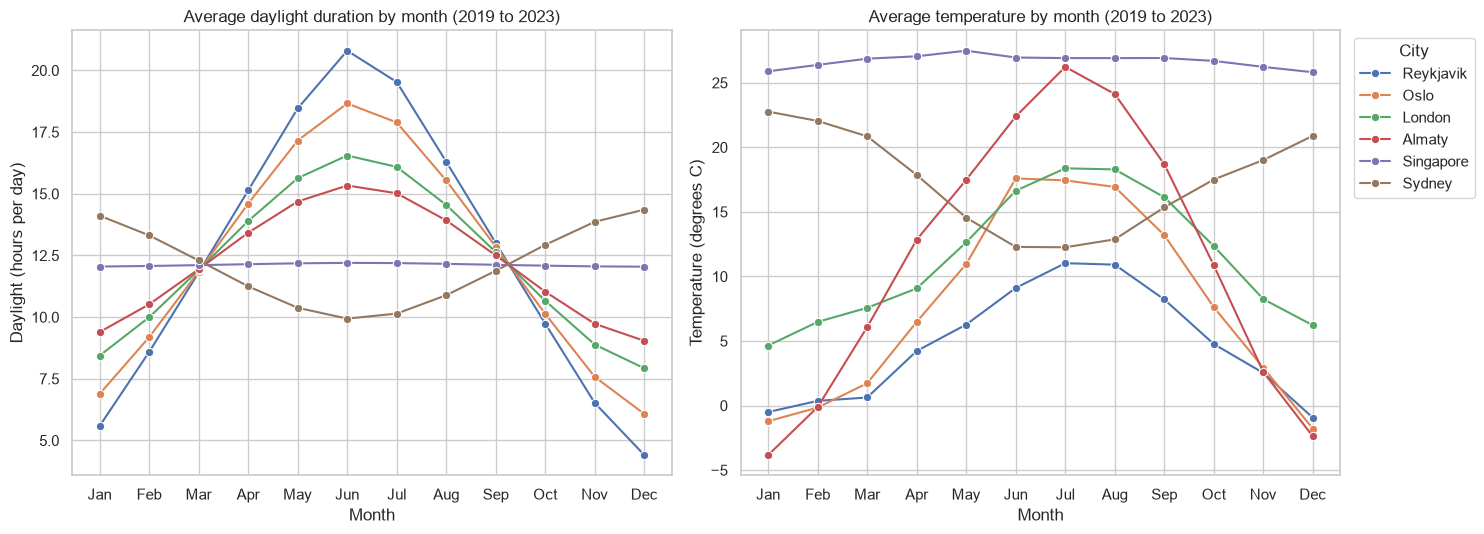

In [17]:
focus = ["Reykjavik", "Oslo", "London", "Almaty", "Singapore", "Sydney"]
month_labels = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
sub = monthly[monthly["city"].isin(focus)]

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
sns.lineplot(data=sub, x="month", y="daylight_h", hue="city", hue_order=focus,
             marker="o", ax=axes[0])
axes[0].set_title("Average daylight duration by month (2019 to 2023)")
axes[0].set_xlabel("Month")
axes[0].set_ylabel("Daylight (hours per day)")

sns.lineplot(data=sub, x="month", y="temp_c", hue="city", hue_order=focus,
             marker="o", ax=axes[1])
axes[1].set_title("Average temperature by month (2019 to 2023)")
axes[1].set_xlabel("Month")
axes[1].set_ylabel("Temperature (degrees C)")

for ax in axes:
    ax.set_xticks(range(1, 13))
    ax.set_xticklabels(month_labels)
axes[1].legend(title="City", loc="upper left", bbox_to_anchor=(1.01, 1))
axes[0].get_legend().remove()
plt.tight_layout()
plt.savefig(FIG_DIR / "plot1_seasonal_profiles.png", dpi=150, bbox_inches="tight")
plt.show()

### Plot 2: Seasonal swing in daylight versus suicide rate

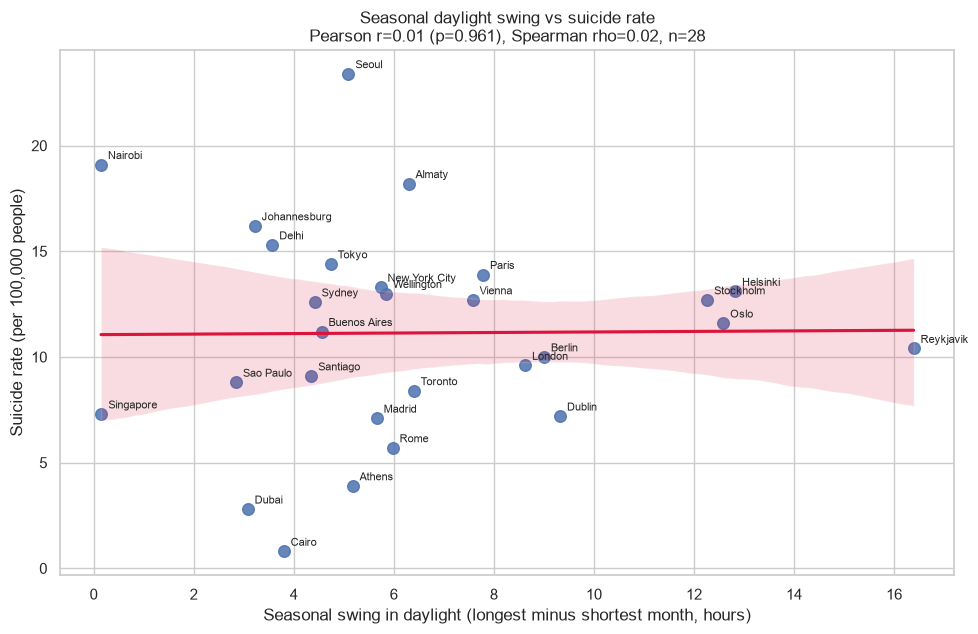

In [18]:
plot_df = df.dropna(subset=["daylight_range", "suicide_rate"])

fig, ax = plt.subplots(figsize=(10, 6.5))
sns.regplot(data=plot_df, x="daylight_range", y="suicide_rate", ax=ax,
            scatter_kws={"s": 70, "alpha": 0.85}, line_kws={"color": "crimson"})
for _, row in plot_df.iterrows():
    ax.annotate(row["city"], (row["daylight_range"], row["suicide_rate"]),
                textcoords="offset points", xytext=(5, 4), fontsize=8)

r, p = st.pearsonr(plot_df["daylight_range"], plot_df["suicide_rate"])
rho, p_s = st.spearmanr(plot_df["daylight_range"], plot_df["suicide_rate"])
ax.set_title(f"Seasonal daylight swing vs suicide rate\nPearson r={r:.2f} (p={p:.3f}), Spearman rho={rho:.2f}, n={len(plot_df)}")
ax.set_xlabel("Seasonal swing in daylight (longest minus shortest month, hours)")
ax.set_ylabel("Suicide rate (per 100,000 people)")
plt.tight_layout()
plt.savefig(FIG_DIR / "plot2_daylight_swing_vs_suicide.png", dpi=150)
plt.show()

### Plot 3: Correlation heatmap

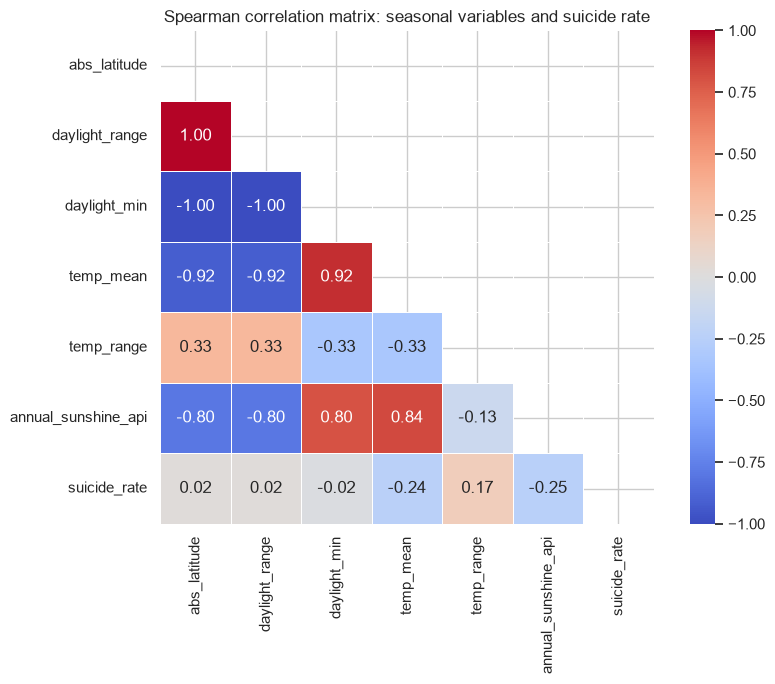

In [19]:
heat_cols = ["abs_latitude", "daylight_range", "daylight_min",
             "temp_mean", "temp_range", "annual_sunshine_api", "suicide_rate"]
corr = df[heat_cols].corr(method="spearman")

fig, ax = plt.subplots(figsize=(9, 7))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            vmin=-1, vmax=1, square=True, linewidths=0.5, ax=ax)
ax.set_title("Spearman correlation matrix: seasonal variables and suicide rate")
plt.tight_layout()
plt.savefig(FIG_DIR / "plot3_correlation_heatmap.png", dpi=150)
plt.show()

### Plot 4: Suicide rate by latitude group

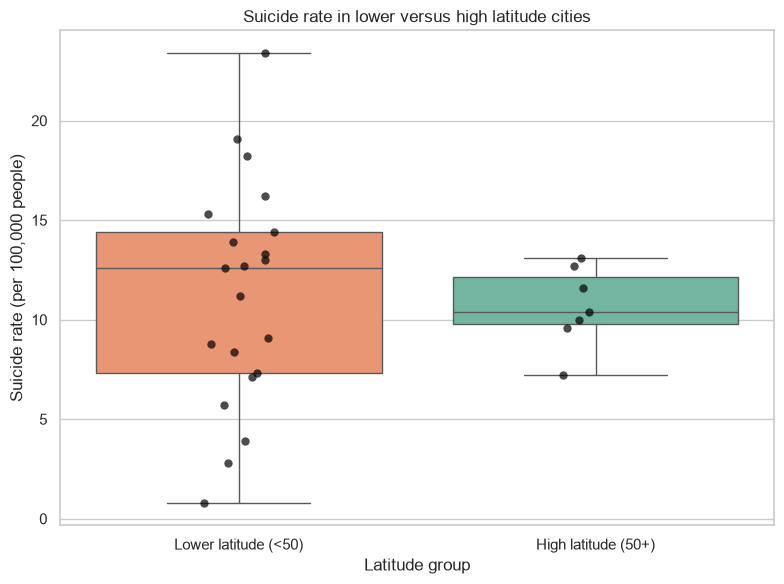

In [20]:
order = ["Lower latitude (<50)", "High latitude (50+)"]
box_df = df.dropna(subset=["suicide_rate"])

fig, ax = plt.subplots(figsize=(8, 6))
sns.boxplot(data=box_df, x="lat_group", y="suicide_rate", order=order, ax=ax,
            hue="lat_group", palette="Set2", legend=False, showfliers=False)
sns.stripplot(data=box_df, x="lat_group", y="suicide_rate", order=order, ax=ax,
              color="black", size=6, alpha=0.7)
ax.set_title("Suicide rate in lower versus high latitude cities")
ax.set_xlabel("Latitude group")
ax.set_ylabel("Suicide rate (per 100,000 people)")
plt.tight_layout()
plt.savefig(FIG_DIR / "plot4_latitude_groups.png", dpi=150)
plt.show()

### Plot 5: Latitude, daylight swing and mean temperature together

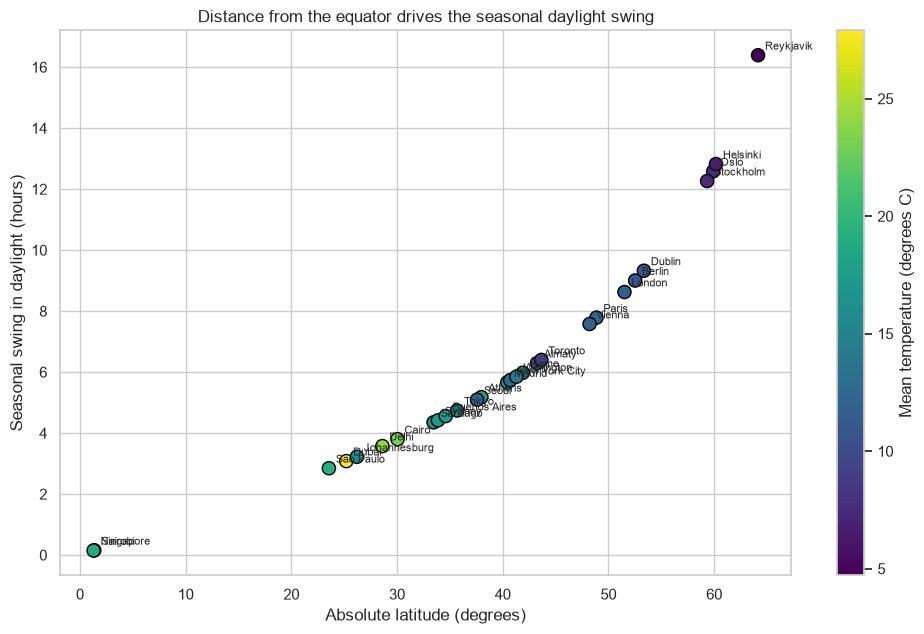

In [21]:
fig, ax = plt.subplots(figsize=(10, 6.5))
sc = ax.scatter(df["abs_latitude"], df["daylight_range"], c=df["temp_mean"],
                cmap="viridis", s=90, edgecolor="black")
for _, row in df.iterrows():
    ax.annotate(row["city"], (row["abs_latitude"], row["daylight_range"]),
                textcoords="offset points", xytext=(5, 4), fontsize=8)
cbar = plt.colorbar(sc, ax=ax)
cbar.set_label("Mean temperature (degrees C)")
ax.set_title("Distance from the equator drives the seasonal daylight swing")
ax.set_xlabel("Absolute latitude (degrees)")
ax.set_ylabel("Seasonal swing in daylight (hours)")
plt.tight_layout()
plt.savefig(FIG_DIR / "plot5_latitude_vs_daylight_swing.png", dpi=150)
plt.show()

## 9. Save the final dataset and summary

In [22]:
df.round(3).to_csv(DATA_DIR / "final_city_dataset.csv", index=False)
monthly.round(3).to_csv(DATA_DIR / "monthly_city_weather.csv", index=False)
print("Saved:", DATA_DIR / "final_city_dataset.csv")

# Automatic summary of the strongest relationships found
if len(corr_table):
    top = corr_table.iloc[0]
    print(f"\nStrongest association with suicide rate: {top['feature']} "
          f"(Spearman rho={top['spearman_rho']}, p={top['spearman_p']}, n={int(top['n'])})")
print(f"Cities analysed: {len(df)} | with a suicide rate: {df['suicide_rate'].notna().sum()}")

Saved: data/final_city_dataset.csv

Strongest association with suicide rate: annual_sunshine_api (Spearman rho=-0.246, p=0.206, n=28)
Cities analysed: 28 | with a suicide rate: 28


## 10. Conclusions and limitations

The numbers below come from the run of this notebook on 29 October 2026 (weather 2019 to 2023, Wikipedia pages as of that date).

**Hypothesis 2: the weather data is consistent (confirmed).**
The seasonal swing in daylight grows steadily with distance from the equator, from about 0.15 hours in Nairobi and Singapore to more than 16 hours in Reykjavik (Plot 5). Within each city, monthly temperature follows monthly daylight closely (mean r = 0.83, lowest r = 0.54), so the API data behaves as expected (Plot 1).

**Hypothesis 3: API and Wikipedia sunshine (partly confirmed).**
The two sources rank the cities in almost the same order (Pearson r = 0.91, Spearman rho = 0.92). However, the absolute values do not agree: the API gives about 3,272 sunshine hours per year on average, while Wikipedia gives about 2,260. For individual cities the API value is 1.1 to 1.9 times the Wikipedia value (about 1.5 times on average), and the paired t-test confirms that this difference is systematic (t = 21.5, p < 0.001). Open-Meteo sunshine duration is a model estimate based on solar radiation, while Wikipedia uses station measurements, so the API values are useful for comparing cities but should not be read as exact hours.

**Hypothesis 1: seasonality and the suicide rate (not supported).**
* None of the seasonal features is significantly related to the suicide rate. Latitude, daylight swing and the shortest winter day show practically no association (Spearman rho about 0.02, p = 0.91).
* The strongest values are weak negative associations with annual sunshine (rho = -0.25, p = 0.21) and mean temperature (rho = -0.24, p = 0.22). After the Bonferroni correction all p-values equal 1.
* High latitude cities (50 degrees and above, n = 7) do not have higher suicide rates than the rest (n = 21): the means are 10.7 and 11.3 per 100,000, and the difference is not significant (Welch t-test p = 0.67, Mann-Whitney p = 0.73, Plot 4).
* The weak negative tendency with sunshine and temperature depends almost entirely on Cairo and Dubai, the two sunniest cities, which report the lowest rates (0.8 and 2.8). Without these two cities the association disappears (rho about -0.07, p about 0.7). Low reported rates in these countries may also reflect under-reporting.
* The highest rates are in Seoul (23.4), Nairobi (19.1), Almaty (18.2) and Johannesburg (16.2). These cities have very different climates and small to moderate daylight swings, which suggests that national factors matter more than seasonality.

**Overall answer to the research question.** In this sample of 28 cities we found no evidence that daylight duration, seasonal swing, sunshine or temperature are related to the national suicide rate.

**Data update note.** An earlier run with an older version of the Wikipedia table showed a weak positive association with latitude (rho about 0.39, p about 0.04). After the page was updated with newer statistics, this association disappeared. This shows that the result is not robust: with only 28 data points, a change in the source data is enough to change the conclusion.

**Limitations**

1. **Proxy indicator.** Suicide rate is not the same as seasonal affective disorder or general well-being. It is only a population level proxy.
2. **Country level versus city level.** The mental health value belongs to a whole country, while the weather belongs to one city.
3. **Small sample.** There are only 28 cities, so correlations are unstable and single cities can change the result.
4. **Ecological fallacy and confounding.** Income, healthcare, culture, alcohol use, religion and reporting practices differ between countries and are related to latitude. A correlation, or the lack of one, at country level says nothing about individual people.
5. **Different time frames.** Weather covers 2019 to 2023, while the Wikipedia statistics use the year chosen by the page authors.
6. **Changing source.** Wikipedia pages are edited over time (the column name and the values changed between runs), so the raw HTML is cached in `data/` to keep the analysis reproducible.

**Possible extensions**

* Add more cities per country, or use a city level well-being measure.
* Control for GDP per capita (World Bank API) with a multiple regression.
* Study month by month patterns if monthly mental health data becomes available.